<a href="https://colab.research.google.com/github/HamzaEric/aapl_volatility_modelling/blob/main/Notebooks/data_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Project context

This project is about assembling an **end-to-end volatility system**:
fetch data → store it → model it → deploy it. This lesson owns the **data
layer** — a small Python module called `data` containing two classes:

| Class | Responsibility | Key methods |
|---|---|---|
| `yfinance` | request daily OHLCV prices and return a clean DataFrame | `get_daily_data` |
| `SQLRepository` | write DataFrames to SQLite and read them back | `insert_table`, `read_table` |

In [12]:
import sqlite3
import matplotlib.pyplot as plt

from yf_loader import get_daily_data
from data import SQLRepository, wrangle_data
import pandas as pd

In [13]:
ticker_aapl = "AAPL"

df_aapl = get_daily_data(symbol=ticker_aapl, period="max")

print("df_aapl type:", type(df_aapl))
print("df_aapl shape:", df_aapl.shape)
df_aapl.head()

df_aapl type: <class 'pandas.core.frame.DataFrame'>
df_aapl shape: (11569, 5)


,open,high,low,close,volume
date,,,,,
1980-12-12,0.098122,0.098549,0.098122,0.098122,469033600
1980-12-15,0.093430,0.093430,0.093003,0.093003,175884800
1980-12-16,0.086604,0.086604,0.086177,0.086177,105728000
1980-12-17,0.088310,0.088737,0.088310,0.088310,86441600
1980-12-18,0.090870,0.091297,0.090870,0.090870,73449600


# Assertion Test On `get_daily_data()`

In [14]:
# Is df_aapl a DataFrame?
assert isinstance(
    df_aapl, pd.DataFrame
), f"Expected pd.DataFrame, got {type(df_aapl)}"

# Does it have exactly 5 columns?
assert (
    df_aapl.shape[1] == 5
), f"Expected 5 columns, got {df_aapl.shape[1]}"

# Does it have a DatetimeIndex?
assert isinstance(
    df_aapl.index, pd.DatetimeIndex
), f"Expected DatetimeIndex, got {type(df_aapl.index)}"

# Is the index named 'date'?
assert (
    df_aapl.index.name == "date"
), f"Expected index name 'date', got '{df_aapl.index.name}'"

# Are the column names correct?
expected_cols = ["open", "high", "low", "close", "volume"]
assert (
    df_aapl.columns.tolist() == expected_cols
), f"Expected columns {expected_cols}, got {df_aapl.columns.tolist()}"

# Are all column dtypes numeric (float or int)?
assert all(
    pd.api.types.is_numeric_dtype(dtype) for dtype in df_aapl.dtypes
), f"Column dtypes: {df_aapl.dtypes.tolist()}"

print("All yf_loader data tests passed.")

All yf_loader data tests passed.


# Building `SQLRepository` class

Calling the API every time you want to analyse a stock is slow and
wasteful. You need to persist the data locally so it can be reloaded
instantly. A SQLite database fits perfectly: a single file, no server, and
native Python integration.

In [15]:
connection = sqlite3.connect(
    database="stocks.sqlite", check_same_thread=False
)
print("connection type:", type(connection))

connection type: <class 'sqlite3.Connection'>


In [16]:
from data import SQLRepository

repo = SQLRepository(connection=connection)

# Test: does repo have a 'connection' attribute?
assert hasattr(repo, "connection"), "SQLRepository missing 'connection' attribute"

# Test: is it a sqlite3.Connection?
assert isinstance(repo.connection, sqlite3.Connection), (
    f"Expected sqlite3.Connection, got {type(repo.connection)}"
)
print("SQLRepository __init__ tests passed.")

SQLRepository __init__ tests passed.


# `insert_table` to store the AAPL data

In [17]:
response = repo.insert_table(
    table_name=ticker_aapl,
    records=df_aapl,
    if_exists="replace"
)

# Print the response dictionary to verify
print("Response:", response)

Response: {'transaction_successful': True, 'records_inserted': 11569}


# `read_table` to read back the AAPL data

In [18]:
# Read the data back from the SQLite database
df_aapl = repo.read_table(
    table_name=ticker_aapl,
    limit=2500
)

print("read_table tests passed.")
print("df_aapl shape:", df_aapl.shape)
df_aapl.head()

read_table tests passed.
df_aapl shape: (2500, 5)


,open,high,low,close,volume
date,,,,,
1980-12-12,0.098122,0.098549,0.098122,0.098122,469033600.0
1980-12-15,0.093430,0.093430,0.093003,0.093003,175884800.0
1980-12-16,0.086604,0.086604,0.086177,0.086177,105728000.0
1980-12-17,0.088310,0.088737,0.088310,0.088310,86441600.0
1980-12-18,0.090870,0.091297,0.090870,0.090870,73449600.0


### Checkpoint

> This Checkpoint closes the loop on persistence: it asserts that what
> came **out** of `read_table` matches the contract that went **in** —
> DataFrame type, `DatetimeIndex` named `date`, five float columns. If the
> round-trip altered the schema, this gate would catch it.

In [19]:
# --- SQLRepository checkpoint ---
assert isinstance(
    repo.connection, sqlite3.Connection
), "repo.connection is not a sqlite3.Connection"

assert isinstance(
    df_aapl, pd.DataFrame
), f"df_aapl should be a DataFrame, got {type(df_aapl)}"

assert isinstance(
    df_aapl.index, pd.DatetimeIndex
), f"Index should be DatetimeIndex, got {type(df_aapl.index)}"

assert df_aapl.index.name == "date", (
    f"Index name should be 'date', got '{df_aapl.index.name}'"
)

assert df_aapl.shape[1] == 5, (
    f"Expected 5 columns, got {df_aapl.shape[1]}"
)

# yfinance returns volume as int, so we check for any numeric dtype
assert all(
    pd.api.types.is_numeric_dtype(dtype) for dtype in df_aapl.dtypes
), f"All columns should be numeric: {df_aapl.dtypes.tolist()}"

print(
    "Checkpoint passed: SQLRepository insert and read work "
    f"correctly. df_aapl shape: {df_aapl.shape}."
)

Checkpoint passed: SQLRepository insert and read work correctly. df_aapl shape: (2500, 5).


> Passing here means insert-and-read is **lossless**: the data you store
> is the data you get back. The repository is now a dependable cache for
> the rest of the project.


 One stock isn't enough to *compare* volatility. Let's run the full
pipeline on a second one.

# Testing the data pipeline on a second stock

In [20]:
ticker_nvda = "NVDA"

df_nvda = get_daily_data(symbol=ticker_nvda, period="max")

# Insert into database
response = repo.insert_table(
    table_name=ticker_nvda,
    records=df_nvda,
    if_exists="replace",
)
print("insert response:", response)

insert response: {'transaction_successful': True, 'records_inserted': 6992}


In [21]:
df_nvda = repo.read_table(
    table_name=ticker_nvda, limit=2500
)
print("df_nvda shape:", df_nvda.shape)
df_nvda.head()

df_nvda shape: (2500, 5)


,open,high,low,close,volume
date,,,,,
1999-01-22,0.040018,0.044663,0.035492,0.037517,2.714688e+09
1999-01-25,0.040494,0.041923,0.037517,0.041448,5.104800e+08
1999-01-26,0.041923,0.042757,0.037636,0.038231,3.432000e+08
1999-01-27,0.038350,0.039303,0.036206,0.038113,2.443680e+08
1999-01-28,0.038113,0.038350,0.037755,0.037993,2.275200e+08


# Checkpoint

In [22]:
# --- Second stock checkpoint ---
assert isinstance(
    df_nvda, pd.DataFrame
), f"df_nvda should be a DataFrame, got {type(df_nvda)}"
assert df_nvda.shape[0] > 0, "df_nvda is empty"
assert df_nvda.shape[1] == 5, (
    f"Expected 5 columns, got {df_nvda.shape[1]}"
)
assert isinstance(
    df_nvda.index, pd.DatetimeIndex
), f"Index should be DatetimeIndex, got {type(df_nvda.index)}"
print(
    "Checkpoint passed: nvda data loaded with shape "
    f"{df_nvda.shape}."
)

Checkpoint passed: nvda data loaded with shape (2500, 5).


# Stock Returns

Comparing stocks by raw price is misleading: prices differ enormously
between companies, and a stock at ₹500 is not "better" than one at ₹20.
**Returns** — the percentage change from one day to the next — put every
stock on a common scale and reveal how volatile each one is.

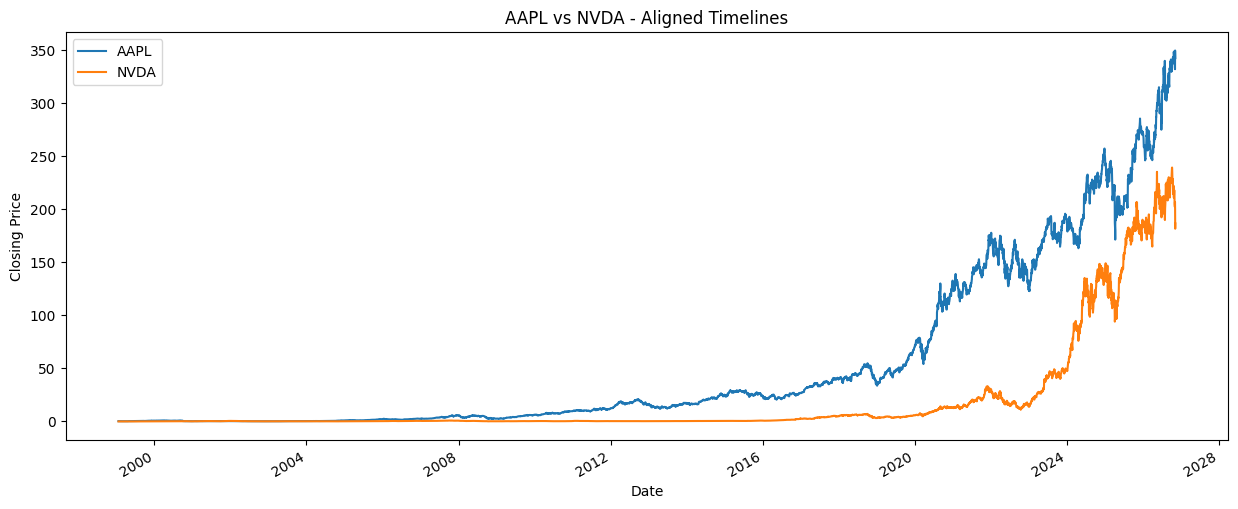

In [25]:
df_aapl = repo.read_table("AAPL")
df_nvda = repo.read_table("NVDA")

df_aapl.sort_index(inplace=True)
df_nvda.sort_index(inplace=True)

common_start = max(df_aapl.index.min(), df_nvda.index.min())

df_aapl = df_aapl.loc[common_start:]
df_nvda = df_nvda.loc[common_start:]

fig, ax = plt.subplots(figsize=(15, 6))
df_aapl["close"].plot(ax=ax, label="AAPL")
df_nvda["close"].plot(ax=ax, label="NVDA")

ax.set_xlabel("Date")
ax.set_ylabel("Closing Price")
ax.set_title("AAPL vs NVDA - Aligned Timelines")
ax.legend()
plt.show()

# Daily Returns

In [26]:
# Compute daily returns
df_aapl["return"] = df_aapl["close"].pct_change() * 100
df_nvda["return"] = df_nvda["close"].pct_change() * 100

print("aapl returns (head):")
print(df_aapl[["close", "return"]].head())
print("\nnvda returns (head):")
print(df_nvda[["close", "return"]].head())

aapl returns (head):
               close    return
date                          
1999-01-22  0.289749       NaN
1999-01-25  0.294423  1.613093
1999-01-26  0.302835  2.856959
1999-01-27  0.300031 -0.925832
1999-01-28  0.305639  1.869027

nvda returns (head):
               close     return
date                           
1999-01-22  0.037517        NaN
1999-01-25  0.041448  10.476395
1999-01-26  0.038231  -7.759339
1999-01-27  0.038113  -0.311049
1999-01-28  0.037993  -0.314395


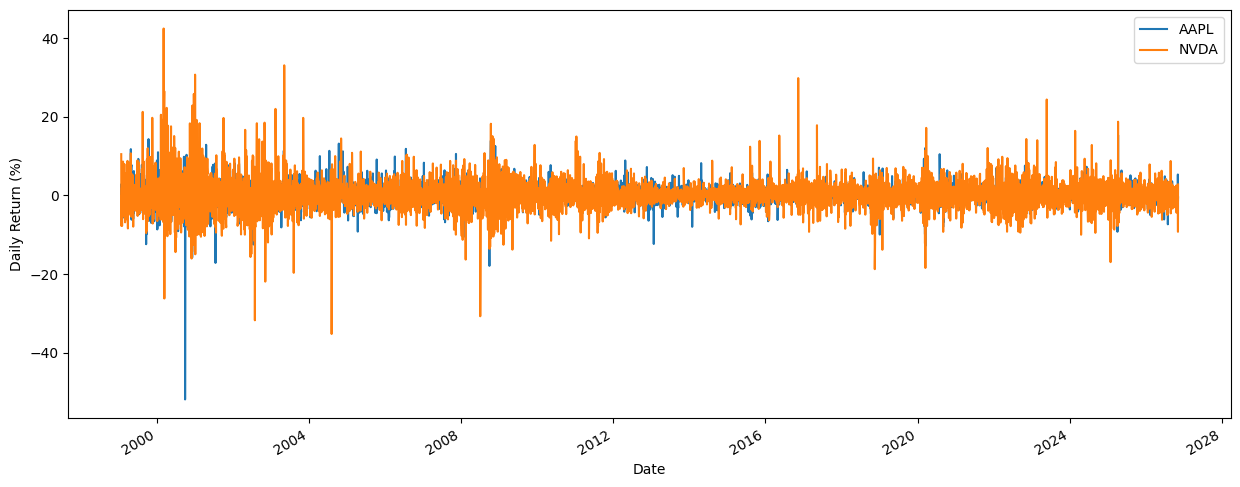

In [29]:
fig, ax = plt.subplots(figsize=(15, 6))
df_aapl["return"].plot(ax=ax, label="AAPL")
df_nvda["return"].plot(ax=ax, label="NVDA")
ax.set_xlabel("Date")
ax.set_ylabel("Daily Return (%)")
ax.legend()
plt.show()

> Reading the return chart
>
> On a common scale the **width of the bands** tells the story: the stock
> with the wider swings is the more volatile one. You should also see the
> stylized fact reappear — turbulent stretches and calm stretches
> arrive in **runs** (volatility clustering), foreshadowing the GARCH
> models of Lesson 3.

In [30]:
# --- Returns checkpoint ---
assert "return" in df_aapl.columns, (
    "df_aapl is missing the 'return' column"
)
assert "return" in df_nvda.columns, (
    "df_nvda is missing the 'return' column"
)
assert df_aapl.shape[1] == 6, (
    f"df_aapl should have 6 columns (5 + return), "
    f"got {df_aapl.shape[1]}"
)
assert df_nvda.shape[1] == 6, (
    f"df_nvda should have 6 columns (5 + return), "
    f"got {df_nvda.shape[1]}"
)
# First return should be NaN (no previous price)
assert pd.isna(df_aapl["return"].iloc[0]), (
    "First return value should be NaN"
)
print(
    "Checkpoint passed: return columns computed correctly."
)

Checkpoint passed: return columns computed correctly.
